# Conductivity of large disordered systems

The conductivity of a disordered sample needs a supercell of $10^4$ to $10^6$
orbitals, too large for a band structure. Here we compute it from a Chebyshev
expansion of the Hamiltonian, with random vectors for the trace, so the cost
grows linearly with the number of orbitals. The absorptive part of the optical
conductivity is

$$\sigma^{H}_{ab}(\omega) = \frac{\pi}{V}\int dE\,\frac{f(E)-f(E+\omega)}{\omega}\,
{\rm Tr}\left[v_b\,\delta(E-H)\,v_a\,\delta(E+\omega-H)\right],$$

with each delta function expanded in Chebyshev polynomials, and the reactive part
follows from the absorption at all frequencies by the Kramers-Kronig relation. We
start with a gapped honeycomb supercell with onsite disorder.

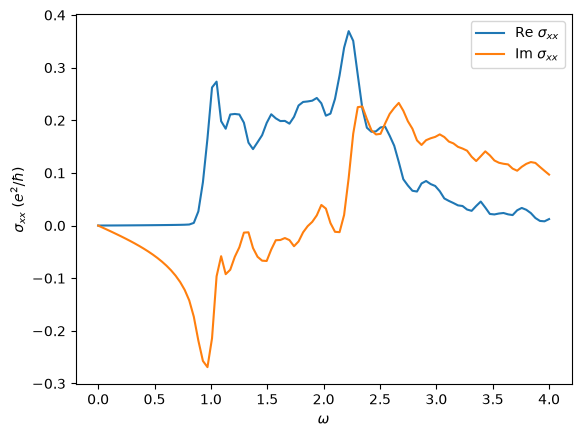

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry
np.random.seed(1)
g = geometry.honeycomb_lattice().get_supercell(30) # 1800 sites
h = g.get_hamiltonian(has_spin=False,is_sparse=True)
h.add_sublattice_imbalance(0.5) # gap of 1
h.add_onsite(lambda r: 0.6*(np.random.random()-0.5)) # onsite disorder
ws = np.linspace(0.,4.,100) # frequencies
(ws,s) = h.get_optical_conductivity(energies=ws,integration="kpm",delta=0.05,ntries=4)
plt.plot(ws,s[:,0,0].real,label=r"Re $\sigma_{xx}$")
plt.plot(ws,s[:,0,0].imag,label=r"Im $\sigma_{xx}$")
plt.xlabel(r"$\omega$") ; plt.ylabel(r"$\sigma_{xx}$ ($e^2/\hbar$)") ; plt.legend()
plt.show()

The absorption ${\rm Re}\,\sigma_{xx}$ is zero below the gap and rises at
$\omega\approx1$. The reactive part ${\rm Im}\,\sigma_{xx}$ is negative below the
gap, as for a dielectric, and changes sign near the maximum of the absorption.

Repeating the absorption for increasing disorder gives a map as a function of the
frequency and of the disorder strength $W$. The disorder fills the gap with states
and smears the absorption edge, and the absorption spreads over a wider range of
frequencies. Here we keep only
the absorptive part, `reactive=False`, which is cheaper.

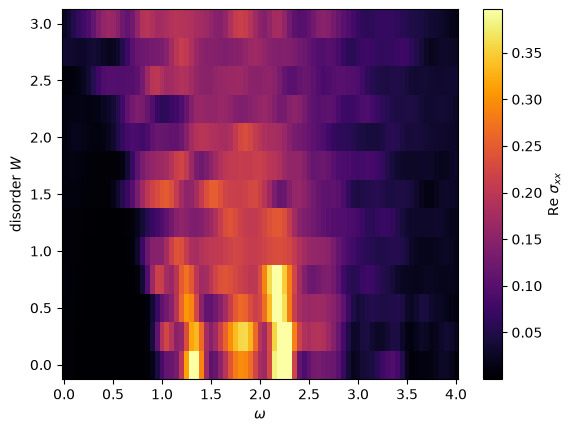

In [2]:
np.random.seed(2)
g = geometry.honeycomb_lattice().get_supercell(20) # 800 sites
Ws = np.linspace(0.,3.,13) # disorder strengths
ws = np.linspace(0.,4.,81)
amap = []
for W in Ws:
    h = g.get_hamiltonian(has_spin=False,is_sparse=True)
    h.add_sublattice_imbalance(0.5)
    h.add_onsite(lambda r: W*(np.random.random()-0.5))
    (ws,s) = h.get_optical_conductivity(energies=ws,integration="kpm",delta=0.1,
                                        ntries=2,reactive=False)
    amap.append(s[:,0,0].real)
plt.pcolormesh(ws,Ws,np.array(amap),cmap="inferno",shading="auto",
               vmax=np.percentile(amap,99))
plt.colorbar(label=r"Re $\sigma_{xx}$")
plt.xlabel(r"$\omega$") ; plt.ylabel("disorder $W$")
plt.show()

The DC tensor is `h.get_dc_conductivity()`. Its default is the Kubo-Bastin
formula, which keeps the states of the Fermi sea, so in the gap of a Chern insulator
it gives the quantized Hall conductivity $2\pi\sigma_{xy}=-C$. The same plateau is
the $\omega\to0$ limit of ${\rm Re}\,\sigma_{xy}(\omega)$ from the optical
conductivity, which never uses the Kubo-Bastin formula. Below we compare the two on
a Haldane supercell, at several Fermi levels.

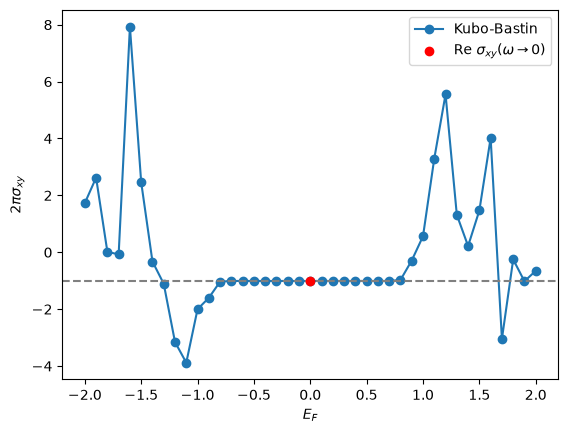

In [3]:
g = geometry.honeycomb_lattice().get_supercell(10) # 200 sites
h = g.get_hamiltonian(has_spin=False,is_sparse=True)
h.add_haldane(0.2) # Chern insulator, C=1, bulk gap of 1.8
fermis = np.linspace(-2.,2.,41)
s = h.get_dc_conductivity(fermi=fermis,delta=0.1,T=0.02,ntries=4) # Kubo-Bastin
(w0,so) = h.get_optical_conductivity(energies=[0.],integration="kpm",delta=0.1,
                                     T=0.02,ntries=4) # optical, Fermi level at zero
plt.plot(fermis,2*np.pi*s[:,0,1],marker="o",label="Kubo-Bastin")
plt.scatter([0.],[2*np.pi*so[0,0,1].real],c="red",zorder=3,label=r"Re $\sigma_{xy}(\omega\to0)$")
plt.axhline(-1.,ls="--",c="gray")
plt.xlabel("$E_F$") ; plt.ylabel(r"$2\pi\sigma_{xy}$") ; plt.legend()
plt.show()

Inside the gap, $|E_F|<0.9$, both give $-1$ within the error of the random
vectors. Outside the gap this cell of 200 sites at the Gamma point has discrete
levels inside the bands, and its Hall conductivity fluctuates strongly from one Fermi
level to the next; a larger cell or more k-points smooths it.

For the longitudinal conductivity of a metal, `mode="singleshot"` uses the
Kubo-Greenwood formula at zero temperature,
$\sigma_{aa}(E_F)={\rm Tr}[v_a\,{\rm Im}G\,v_a\,{\rm Im}G]/(\pi V)$ with
$G=(E_F+i\delta/2-H)^{-1}$, one Chebyshev series per Fermi level, at a cost that grows
as $1/\delta$. We compute it for disordered graphene at two values of $\delta$: the
result is converged when it no longer changes with $\delta$.

delta = 0.1 : sigma_xx(E_F=0) = 0.106


delta = 0.05 : sigma_xx(E_F=0) = 0.11


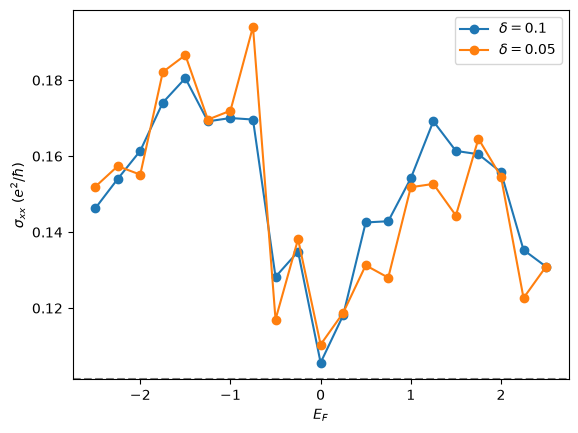

In [4]:
np.random.seed(1)
g = geometry.honeycomb_lattice().get_supercell(40) # 3200 sites
h = g.get_hamiltonian(has_spin=False,is_sparse=True)
h.add_onsite(lambda r: 3.0*(np.random.random()-0.5)) # Anderson disorder
fermis = np.linspace(-2.5,2.5,21)
for delta in [0.1,0.05]:
    sxx = h.get_dc_conductivity(fermi=fermis,delta=delta,mode="singleshot",
                                component="xx",ntries=16,seed=1)
    print("delta =",delta,": sigma_xx(E_F=0) =",round(sxx[10],3))
    plt.plot(fermis,sxx,marker="o",label=r"$\delta=$"+str(delta))
plt.axhline(2/(np.pi*2*np.pi),ls="--",c="gray") # 2e^2/(pi h) in units of e^2/hbar
plt.xlabel("$E_F$") ; plt.ylabel(r"$\sigma_{xx}$ ($e^2/\hbar$)") ; plt.legend()
plt.show()

The two values of $\delta$ give the same curve within the noise of the random
vectors, which is larger for the smaller $\delta$, so the broadening is below the
scattering rate of the disorder. At the Dirac point the conductivity is about $0.11$,
of the order of the dashed line, $2e^2/(\pi h)\approx0.10$, the value per spin that
Ref. [2] finds at the Dirac point of graphene with vacancies. Onsite disorder is a
different kind of disorder, so the two need not agree, and a smaller $\delta$ with a
larger cell is needed to settle the value here.

### Comparison with the literature
The DC tensor is the Chebyshev form of the Kubo-Bastin formula of Ref. [1]. The
single-shot Kubo-Greenwood route, with the exact Chebyshev series of the Green's
function at complex energy, is the one of Ref. [2]. The optical conductivity as an
energy integral over delta functions and Green's functions of the Hamiltonian, each
expanded in Chebyshev polynomials, is derived in Ref. [3].

[1] J. H. Garcia, L. Covaci and T. G. Rappoport, Phys. Rev. Lett. 114, 116602, arXiv:1410.8140.
[2] A. Ferreira and E. R. Mucciolo, Phys. Rev. Lett. 115, 106601, arXiv:1507.00488.
[3] S. M. Joao and J. M. Viana Parente Lopes, J. Phys.: Condens. Matter 32, 125901, arXiv:1810.03732.